# Campus Wellbeing Outreach Analysis

**Question:** Where and when should a peer wellbeing table be placed on campus, and which student population should outreach focus on, so that students who would benefit most are likely to encounter it?

**Data:** synthetic student, campus-space, card check-in and wellbeing-survey files (see `data/`).

**Workflow:** load → check → clean → check → join → analyze → visualize → summarize. Every cleaning step prints a before/after count and every check is an `assert`.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

In [2]:
print("data_dictionary")
display(pd.read_csv("data/data_dictionary.csv"))
print("feedback_codebook")
display(pd.read_csv("data/feedback_codebook.csv"))

data_dictionary


,file,field,description,data_type,notes
0,students.csv,student_id,Student identifier,string,6 characters; unique for each student
1,students.csv,academic_level,Student level,categorical,"First-year, Sophomore, Junior, Senior, Graduate"
2,students.csv,college,College,categorical,Six colleges
3,students.csv,first_generation,First-generation status,categorical,"Yes, No, Unknown, or missing"
4,students.csv,commuter_status,Residential or commuter,categorical,"Residential, Commuter, Unknown, or missing"
5,students.csv,entry_term,Initial entry term,string,YYYY-Term
6,students.csv,gpa,Cumulative GPA,numeric,0.00-4.00
7,students.csv,admit_type,Admission type,categorical,"New, Transfer, Graduate, or missing"
8,spaces.csv,space_id,Space identifier,string,4 characters; unique
9,spaces.csv,space_name,Space name,string,NaN


feedback_codebook


,field_name,survey_item_description,data_type,response_coding
0,response_id,Survey response identifier,String,Unique identifier
1,student_id,Student id,String,Student ID
2,survey_date,Date of survey response,Date,YYYY-MM-DD
3,belonging_rating,I feel like part of the campus community.,Ordinal numeric,1 = Strongly disagree; 2 = Disagree; 3 = Neutr...
4,stress_level,How would you rate your stress this month?,Ordinal numeric,1 = Very low; 2 = Low; 3 = Moderate; 4 = High;...
5,loneliness_frequency,How often have you felt isolated recently?,Ordinal numeric,1 = Rarely; 2 = Sometimes; 3 = Often
6,support_rating,How much support do you have from people you t...,Ordinal numeric,1 = None; 2 = A little; 3 = Some; 4 = A lot; 5...
7,resources_awareness,Do you know where to find wellbeing resources ...,Categorical,Yes; No; Not sure
8,food_or_housing_concern,Have food or housing worries affected you this...,Categorical,Yes; No; Prefer not to answer


In [3]:
# load each file into its own table
students = pd.read_csv("data/students.csv")
spaces   = pd.read_csv("data/spaces.csv")
checkins = pd.read_csv("data/checkins.csv")
feedback = pd.read_csv("data/feedback.csv")
print("raw:", students.shape, spaces.shape, checkins.shape, feedback.shape)


raw: (4255, 8) (10, 5) (19109, 6) (1925, 9)


In [4]:
students = pd.read_csv("data/students.csv").drop_duplicates()
spaces   = pd.read_csv("data/spaces.csv").drop_duplicates()
checkins = pd.read_csv("data/checkins.csv").drop_duplicates()
feedback = pd.read_csv("data/feedback.csv").drop_duplicates("student_id")   # one survey per student

print("deduped (rows, columns):", students.shape, spaces.shape, checkins.shape, feedback.shape)

deduped (rows, columns): (4200, 8) (10, 5) (18959, 6) (1890, 9)


In [5]:
def show(title, counts):
    print(f"--- {title} ---")
    print(counts.to_string(header=False), "\n")

#### Check 1: Did everything load, and are the keys unique?

In [6]:
# each ID should appear once in its table, or joins double-count
assert students["student_id"].is_unique, "duplicate student IDs"
assert spaces["space_id"].is_unique, "duplicate space IDs"
assert feedback["student_id"].is_unique, "a student has two surveys"
assert checkins["checkin_id"].is_unique, "duplicate check-in IDs"

for name, df in {"students": students, "spaces": spaces,
                 "checkins": checkins, "feedback": feedback}.items():
    print(f"--- {name} ---")
    print(df.isna().sum(), "\n")


--- students ---
student_id            0
academic_level        0
college               0
first_generation    120
commuter_status      25
entry_term            0
gpa                  40
admit_type           30
dtype: int64 

--- spaces ---
space_id          0
space_name        0
space_type        0
location          0
indoor_outdoor    0
dtype: int64 

--- checkins ---
checkin_id        0
student_id        0
space_id          0
checkin_date     19
checkin_time     16
visit_purpose    50
dtype: int64 

--- feedback ---
response_id                 0
student_id                  0
survey_date                 0
belonging_rating           60
stress_level               59
loneliness_frequency       50
support_rating             60
resources_awareness        12
food_or_housing_concern     0
dtype: int64 



In [7]:
# IDs: same format on both sides of every join
for df in [students, feedback, checkins]:
    df["student_id"] = df["student_id"].str.strip().str.upper()
for df in [spaces, checkins]:
    df["space_id"] = df["space_id"].str.strip().str.upper()

# before: the messy values
show("Commuter status (raw)", students["commuter_status"].value_counts(dropna=False))
show("First generation (raw)", students["first_generation"].value_counts(dropna=False))
show("Stress level (raw)", feedback["stress_level"].value_counts(dropna=False).sort_index())

# clean categories: one spelling each, blanks -> "unknown"
students["commuter_status"]  = students["commuter_status"].str.strip().str.lower().replace({"res": "residential"}).fillna("unknown")
students["first_generation"] = students["first_generation"].str.strip().str.lower().replace({"y": "yes", "n": "no"}).fillna("unknown")
students["admit_type"]       = students["admit_type"].fillna("unknown")

# clean survey ratings: valid ranges from the codebook; anything else -> missing (never guess)
ranges = {"belonging_rating": 5, "stress_level": 5, "support_rating": 5, "loneliness_frequency": 3}
for col, hi in ranges.items():
    feedback[col] = pd.to_numeric(feedback[col], errors="coerce")
    bad = feedback[col].notna() & ~feedback[col].between(1, hi)
    print(f"{col}: {bad.sum()} out of range")
    feedback.loc[bad, col] = None

# clean survey categories: one spelling each
feedback["resources_awareness"]     = feedback["resources_awareness"].str.strip().str.lower().replace({"unsure": "not sure"})
feedback["food_or_housing_concern"] = feedback["food_or_housing_concern"].str.strip().str.lower()

# clean GPA: valid range 0-4

students["gpa"] = pd.to_numeric(students["gpa"], errors="coerce")
print("GPA outside 0-4:", (~students["gpa"].between(0, 4) & students["gpa"].notna()).sum())
students.loc[~students["gpa"].between(0, 4), "gpa"] = None                      # valid GPA 0-4

# after: one line each
print("commuter:", students["commuter_status"].value_counts().to_dict())
print("first gen:", students["first_generation"].value_counts().to_dict())
print("admit type:", students["admit_type"].value_counts().to_dict())
print("stress:", feedback["stress_level"].value_counts().sort_index().to_dict(), "| missing:", feedback["stress_level"].isna().sum())
print("resources awareness:", feedback["resources_awareness"].value_counts(dropna=False).to_dict())
print("GPA missing:", students["gpa"].isna().sum())

--- Commuter status (raw) ---
Commuter       2697
Residential    1413
NaN              25
Unknown          23
commuter         22
Res              20 

--- First generation (raw) ---
No         2262
Yes        1502
Unknown     256
NaN         120
N            19
Y            18
yes          13
no           10 

--- Stress level (raw) ---
0.0       3
1.0      74
2.0     352
3.0     725
4.0     515
5.0     157
6.0       2
9.0       2
99.0      1
NaN      59 

belonging_rating: 8 out of range
stress_level: 8 out of range
support_rating: 8 out of range
loneliness_frequency: 6 out of range
GPA outside 0-4: 25
commuter: {'commuter': 2719, 'residential': 1433, 'unknown': 48}
first gen: {'no': 2291, 'yes': 1533, 'unknown': 376}
admit type: {'New': 2615, 'Transfer': 977, 'Graduate': 578, 'unknown': 30}
stress: {1.0: 74, 2.0: 352, 3.0: 725, 4.0: 515, 5.0: 157} | missing: 67
resources awareness: {'yes': 1134, 'not sure': 388, 'no': 356, nan: 12}
GPA missing: 65


#### Check 2: Are the categories clean and the survey values in range?

In [8]:
assert not checkins["student_id"].str.contains("[a-z]").any(), "lowercase IDs left"
assert set(students["commuter_status"]) <= {"commuter", "residential", "unknown"}
assert set(students["first_generation"]) <= {"yes", "no", "unknown"}
for col, hi in ranges.items():
    assert feedback[col].dropna().between(1, hi).all(), f"{col} out of range"
assert set(feedback["resources_awareness"].dropna()) <= {"yes", "no", "not sure"}
show("Survey values missing after cleaning", feedback[list(ranges)].isna().sum())

--- Survey values missing after cleaning ---
belonging_rating        68
stress_level            67
support_rating          68
loneliness_frequency    56 



In [9]:
# hour from "HH:MM"; bad times like 25:10 become missing (left out of time analysis only)
checkins["hour"] = pd.to_datetime(checkins["checkin_time"], format="%H:%M", errors="coerce").dt.hour

# group hours: before 12 Morning, 12-5 Afternoon, 5 pm on Evening
checkins["period"] = pd.cut(checkins["hour"], bins=[0, 12, 17, 24],
                            labels=["Morning", "Afternoon", "Evening"], right=False)

display(checkins[["checkin_time", "hour", "period"]].head())   # e.g. 09:25 -> 9 -> Morning

,checkin_time,hour,period
0,09:25,9.0,Morning
1,12:00,12.0,Afternoon
2,20:19,20.0,Evening
3,18:18,18.0,Evening
4,20:48,20.0,Evening


#### Check 3: Did every time land in a period?

In [10]:
show("Check-ins by period (NaN = bad or blank time)", checkins["period"].value_counts(dropna=False))
show("Times that couldn't be read", checkins.loc[checkins["hour"].isna(), "checkin_time"].value_counts(dropna=False))

--- Check-ins by period (NaN = bad or blank time) ---
Evening      7445
Afternoon    6360
Morning      5111
NaN            43 

--- Times that couldn't be read ---
25:10    19
NaN      16
99:99     8 



#### Join and save the clean dataset

In [11]:
# join on shared keys; the inner join drops IDs that don't match
visits = checkins.merge(spaces, on="space_id").merge(students, on="student_id")
print(len(checkins), "->", len(visits), "rows;", visits.shape[1], "columns")
display(visits.head(3))

visits.to_csv("outputs/clean_visits.csv", index=False)   # analysis-ready dataset

18959 -> 18870 rows; 19 columns


,checkin_id,student_id,space_id,checkin_date,checkin_time,visit_purpose,hour,period,space_name,space_type,location,indoor_outdoor,academic_level,college,first_generation,commuter_status,entry_term,gpa,admit_type
0,C012915,P55348,S110,2025-10-21,09:25,Meal,9.0,Morning,Parking Structure 3 Bridge,Transit,South Campus,Outdoor,First-year,Health & Human Services,no,commuter,2025-Spring,3.35,New
1,C013101,P91041,S107,2025-11-13,12:00,Study,12.0,Afternoon,Arts Plaza,Outdoor,Central Campus,Outdoor,Junior,Engineering,yes,commuter,2025-Fall,3.16,New
2,C010133,P18756,S104,2025-09-08,20:19,Study,20.0,Evening,Transit Center Plaza,Transit,South Campus,Outdoor,Senior,Education,unknown,commuter,2025-Fall,2.60,New


#### What did the join drop, and why?

In [12]:
print(f"Rows dropped in join: {len(checkins) - len(visits)}")
show("Space IDs not in spaces.csv", checkins.loc[~checkins["space_id"].isin(spaces["space_id"]), "space_id"].value_counts())
print(f"Check-ins with unknown student ID: {(~checkins['student_id'].isin(students['student_id'])).sum()}")
assert len(visits) <= len(checkins), "join created extra rows"

Rows dropped in join: 89
--- Space IDs not in spaces.csv ---
S1O4    10
S199     4 

Check-ins with unknown student ID: 75


## Answering the Question 

### Q1: Which space and time are busiest?
Check-ins by space and time period, sorted by evening traffic.

In [13]:
# Q1: visits by space x period
display(pd.crosstab(visits["space_name"], visits["period"])
          .sort_values("Evening", ascending=False))

period,Morning,Afternoon,Evening
space_name,,,
Transit Center Plaza,1054,972,2946
24-Hour Study Room,127,128,1401
Rec Center Lobby,779,559,837
Library Commons,702,832,524
Parking Structure 3 Bridge,573,659,422
Union Food Court,663,1628,408
Residence Hall Lounge,434,579,329
Engineering Courtyard,286,370,203
Career Center Atrium,237,319,176


### Who visits each space?
Share of each space's check-ins by commuter status, then by first-generation status.

In [14]:
display(pd.crosstab(visits["space_name"], visits["commuter_status"], normalize="index")
          .sort_values("commuter", ascending=False)
          .style.format("{:.0%}"))
display(pd.crosstab(visits["space_name"], visits["first_generation"], normalize="index")
          .sort_values("yes", ascending=False)
          .style.format("{:.0%}"))

commuter_status,commuter,residential,unknown
space_name,,,
Transit Center Plaza,87%,12%,1%
Parking Structure 3 Bridge,85%,14%,1%
24-Hour Study Room,65%,34%,1%
Library Commons,58%,40%,2%
Union Food Court,58%,41%,1%
Career Center Atrium,58%,41%,1%
Engineering Courtyard,58%,40%,2%
Arts Plaza,57%,42%,1%
Rec Center Lobby,52%,47%,1%


first_generation,no,unknown,yes
space_name,,,
Transit Center Plaza,49%,8%,43%
Parking Structure 3 Bridge,51%,9%,40%
24-Hour Study Room,52%,9%,39%
Residence Hall Lounge,55%,10%,35%
Engineering Courtyard,56%,10%,34%
Union Food Court,57%,8%,34%
Library Commons,57%,9%,34%
Arts Plaza,59%,9%,32%
Career Center Atrium,59%,10%,32%


### Q2: Which students need support most?
Survey respondents only. `n` = survey responses; ratings are averages (1-5; loneliness 1-3); `pct_` columns are shares of students.
**High need** = stress 4-5 or often lonely (analyst-defined).

In [15]:
# flags for "share of students" measures
feedback["high_need"]   = (feedback["stress_level"] >= 4) | (feedback["loneliness_frequency"] == 3)
feedback["aware"]       = feedback["resources_awareness"] == "yes"
feedback["basic_needs"] = feedback["food_or_housing_concern"] == "yes"

survey = students.merge(feedback, on="student_id")

for group in ["commuter_status", "first_generation"]:
    table = (survey[survey[group] != "unknown"].groupby(group)
             .agg(n=("response_id", "count"),
                  belonging=("belonging_rating", "mean"), stress=("stress_level", "mean"),
                  support=("support_rating", "mean"), loneliness=("loneliness_frequency", "mean"),
                  pct_high_need=("high_need", "mean"), pct_aware=("aware", "mean"),
                  pct_basic_needs=("basic_needs", "mean")))
    display(table.style.format({"belonging": "{:.2f}", "stress": "{:.2f}", "support": "{:.2f}", "loneliness": "{:.2f}",
                                "pct_high_need": "{:.0%}", "pct_aware": "{:.0%}", "pct_basic_needs": "{:.0%}"}))

,n,belonging,stress,support,loneliness,pct_high_need,pct_aware,pct_basic_needs
commuter_status,,,,,,,,
commuter,1231,3.21,3.27,3.19,1.96,49%,58%,29%
residential,618,3.52,3.00,3.36,1.84,40%,65%,20%


,n,belonging,stress,support,loneliness,pct_high_need,pct_aware,pct_basic_needs
first_generation,,,,,,,,
no,1037,3.41,3.10,3.31,1.83,41%,64%,22%
yes,674,3.12,3.32,3.13,2.07,55%,53%,32%


### Findings
- Transit Center Plaza in the evening has the most check-ins (2,946), nearly double the next busiest slot.
- 87% of its visits are by commuters (8% at the Residence Hall Lounge).
- Commuters are worse off on every wellbeing measure: 49% high need vs 40% of residential students (n = 1,231 vs 618), lower belonging (3.21 vs 3.52), less aware of resources (58% vs 65%), more food or housing worries (29% vs 20%).
- First-gen students show the same pattern: 55% high need vs 41% (n = 674 vs 1,037).

#### Do the totals add up, and what's the survey denominator?

In [16]:
ct = pd.crosstab(visits["space_name"], visits["period"])
assert ct.values.sum() == visits["period"].notna().sum(), "crosstab lost rows"
print(len(survey), "of", len(students), "students answered the survey")   # survey denominator

1870 of 4200 students answered the survey


In [17]:
# CHART STYLE
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # highlight + period colors
GRAY = "#d3d2cc"                                      
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BG = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": INK2, "ytick.left": False, "xtick.bottom": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

def titles(ax, title, subtitle):
    """Bold headline (the finding) + gray subtitle (what the chart shows)."""
    ax.set_title(title, loc="left", pad=30, fontsize=14, fontweight="bold", color=INK)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10.5, color=INK2, va="bottom")

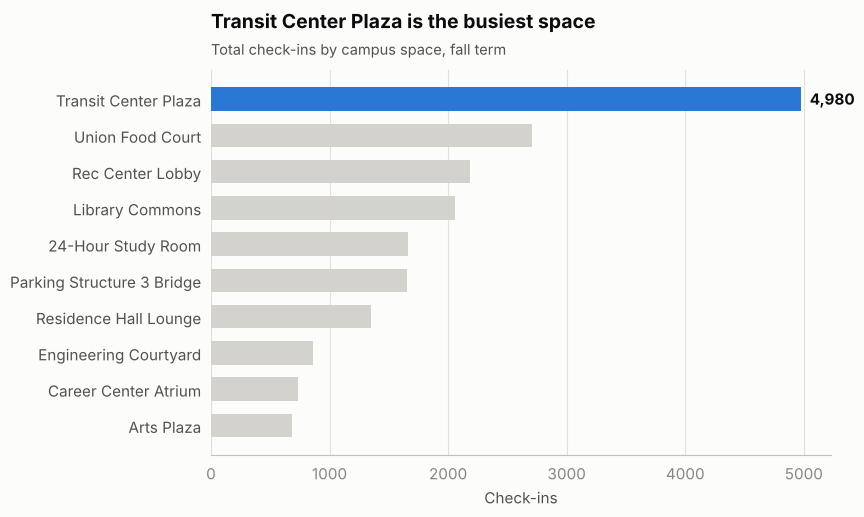

In [18]:
#Chart 1 : Where

counts = visits["space_name"].value_counts().sort_values()
colors = [BLUE if name == "Transit Center Plaza" else GRAY for name in counts.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(counts.index, counts.values, color=colors, height=0.65)
ax.grid(axis="y", visible=False)
ax.bar_label(ax.containers[0], labels=[f"{v:,}" if n == "Transit Center Plaza" else "" for n, v in counts.items()],
             padding=6, fontweight="bold", color=INK)          # label only the answer
ax.set_xlabel("Check-ins")
titles(ax, "Transit Center Plaza is the busiest space", "Total check-ins by campus space, fall term")
plt.savefig("outputs/chart1_where.png")
plt.show()

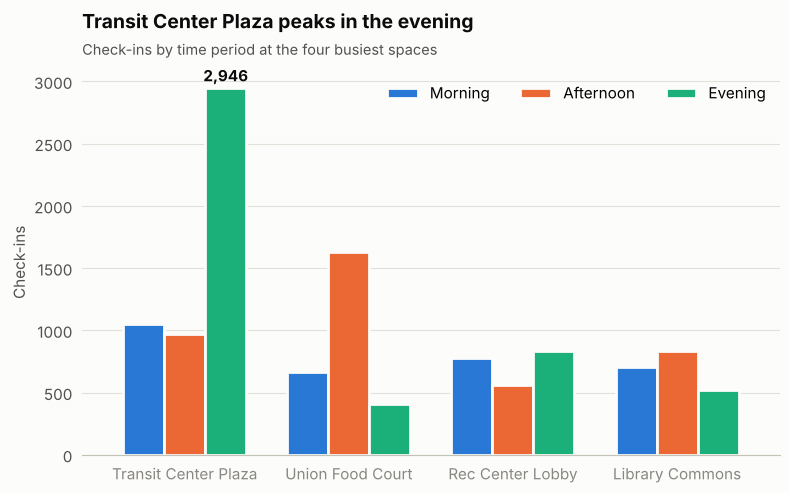

In [19]:
#Chart 2: When

by_period = pd.crosstab(visits["space_name"], visits["period"])
top4 = by_period.sum(axis=1).sort_values(ascending=False).head(4).index

fig, ax = plt.subplots(figsize=(9, 5))
by_period.loc[top4].plot(kind="bar", ax=ax, rot=0, width=0.75,
                         color=[BLUE, ORANGE, AQUA], edgecolor=BG, linewidth=2)   # thin gap between bars
ax.grid(axis="x", visible=False)
ax.set_xlabel("")
ax.set_ylabel("Check-ins")
ax.legend(title="", ncol=3, loc="upper right")
peak = by_period.loc["Transit Center Plaza", "Evening"]
ax.annotate(f"{peak:,}", xy=(0.25, peak), xytext=(0, 5), textcoords="offset points",
            ha="center", fontweight="bold", color=INK)                 # label the peak bar
titles(ax, "Transit Center Plaza peaks in the evening", "Check-ins by time period at the four busiest spaces")
plt.savefig("outputs/chart2_when.png")
plt.show()

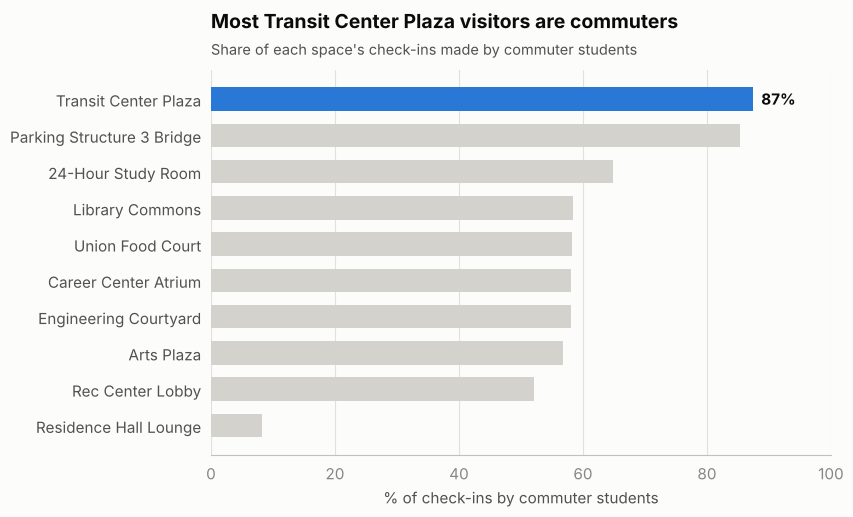

In [20]:
#Chart 3: Who visits

pct = (pd.crosstab(visits["space_name"], visits["commuter_status"], normalize="index")["commuter"] * 100).sort_values()
colors = [BLUE if name == "Transit Center Plaza" else GRAY for name in pct.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pct.index, pct.values, color=colors, height=0.65)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.bar_label(ax.containers[0], labels=[f"{v:.0f}%" if n == "Transit Center Plaza" else "" for n, v in pct.items()],
             padding=6, fontweight="bold", color=INK)
ax.set_xlabel("% of check-ins by commuter students")
titles(ax, "Most Transit Center Plaza visitors are commuters", "Share of each space's check-ins made by commuter students")
plt.savefig("outputs/chart3_who.png")
plt.show()

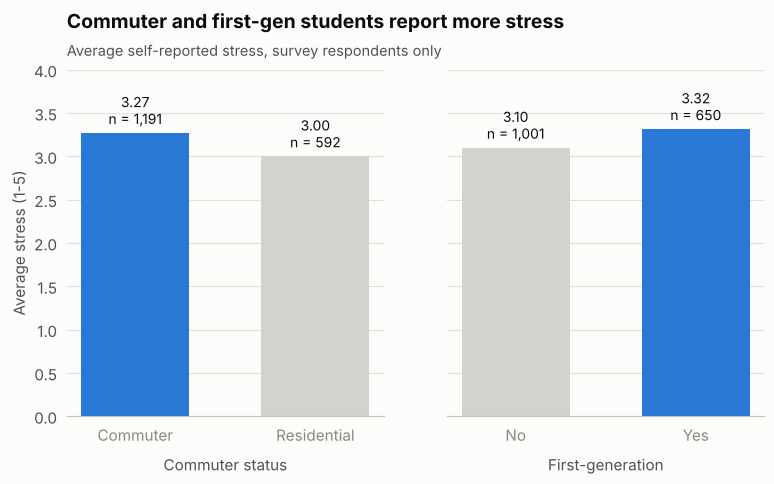

In [21]:
#Chart 4: Who needs it

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)

for ax, col, label in [(axes[0], "commuter_status", "Commuter status"),
                       (axes[1], "first_generation", "First-generation")]:
    g = survey[survey[col] != "unknown"].groupby(col)["stress_level"].agg(["mean", "count"])
    colors = [BLUE if grp in ("commuter", "yes") else GRAY for grp in g.index]
    bars = ax.bar(g.index.str.capitalize(), g["mean"], color=colors, width=0.6)
    ax.bar_label(bars, labels=[f"{m:.2f}\nn = {n:,}" for m, n in zip(g["mean"], g["count"])],
                 padding=4, color=INK, fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 4)
    ax.set_xlabel(label, color=INK2, labelpad=8)

axes[0].set_ylabel("Average stress (1-5)")
titles(axes[0], "Commuter and first-gen students report more stress",
       "Average self-reported stress, survey respondents only")
plt.savefig("outputs/chart4_need.png")
plt.show()

In [22]:
import os
for f in ["clean_visits.csv", "chart1_where.png", "chart2_when.png", "chart3_who.png", "chart4_need.png"]:
    assert os.path.exists("outputs/" + f), f"missing {f}"
print("all checks passed")

all checks passed


### Limitations
- Only about 45% of students answered the survey; respondents may differ from non-respondents.
- Survey answers are self-reported; results show association, not cause.
- Check-ins only capture card swipes, so some visits may be missed.
- One term of data; patterns may differ in other terms.
- "High need" (stress 4–5 or often lonely) is an analyst-defined measure.